# The dependence-uncertainty band and the worst-case VaR bounds

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the simple sum, the square-root rule and the copulas)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- explain why the comonotonic VaR, the VaR of perfectly dependent risks, is not the worst case, and compute the sharp worst and best VaR of a sum for known marginals and any dependence with the rearrangement algorithm;
- watch the rearrangement algorithm work on a matrix small enough to print, and see why it ends with nearly equal row sums;
- build the **band** of the case, the lower bound, the simple sum, the square-root rule, the Gaussian copula, one t copula for each degree of freedom and the worst case, and say which of its rows depend on the correlation matrix and which do not;
- check the band's structural rules with the engine's `worst_case_bracket` test, and read how the market-credit correlation stress moves the committed band;
- say why the case shows the whole band beside the headline capital and never one diversified number.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from riskvalidation.aggregation import band as rv_band
from riskvalidation.aggregation import bounds
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the same case as notebooks 01 and 02, **C18** (Banco Andino).

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginals, matrix, committed band), `data/derived/C18/t-copula-baseline.json` (`outputs.correlation_stress`: the same band with the market-credit correlation raised to 0.8) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`, the marginals' quantile functions).
- **The marginals are rebuilt from the committed quantile grids in the simulated steps.** As in notebook 02, the models document holds each marginal's quantile function on a named grid and not the simulated losses, so step 3 rebuilds the four marginals from it and runs the band on them with the pipeline's settings; the committed band is expected back to within 0.01 percent. Steps 1 and 2 use a published example with closed-form marginals instead, so that the algorithm can be checked against a formula.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
stress = read_json("C18/t-copula-baseline.json")["outputs"]["correlation_stress"]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
print("committed band rows:", len(agg["band"]), "| baked by riskvalidation", baseline["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

derived folder found: True
committed band rows: 8 | baked by riskvalidation 0.9.0 | installed 0.9.0


## Method

### Step 1: the comonotonic VaR is not the worst case

When the dependence between the risks is unknown, a natural but wrong upper bound is the **comonotonic VaR**, the VaR of the sum when the risks move together perfectly: $\mathrm{VaR}_q(L_1 + \dots + L_d) = \sum_k F_k^{-1}(q)$. It is the simple sum of the VaRs, exact for perfect dependence. But **VaR is not subadditive**, so some other dependence can give a larger VaR of the sum (Embrechts, McNeil and Straumann 2002; Embrechts, Puccetti and Rueschendorf 2013). The engine computes the exact best and worst VaR over all dependence structures, given only the marginals.

The published example of Embrechts, Puccetti and Rueschendorf (2013, Table 4) uses Pareto(2) marginals, $F(x) = 1 - (1+x)^{-2}$, so $F^{-1}(q) = (1-q)^{-1/2} - 1$ in closed form, with $d = 8$ risks. The next cell builds the eight quantile functions, evaluates the comonotonic VaR at $q = 0.99$ with `comonotonic_var` and by the closed form, and then computes the worst and best VaR with `worst_var_bounds` ($N = 10^5$ cells, $\epsilon = 10^{-3}$, the settings of the pipeline).

In [3]:
# Eight Pareto(2) marginals of the published example: comonotonic VaR by the engine and by the formula, then the sharp bounds
def pareto_ppf(u):
    # the quantile function of F(x) = 1 - (1 + x)^-2; the last grid cell is exactly 1, where the quantile is +infinity
    with np.errstate(divide="ignore"):
        return (1.0 - np.asarray(u, dtype=float)) ** -0.5 - 1.0


D, Q = 8, 0.99
pareto = [pareto_ppf] * D
print("comonotonic VaR, engine:", round(bounds.comonotonic_var(pareto, Q), 4), "| closed form d * ((1 - q)^(-1/2) - 1):", round(D * ((1 - Q) ** -0.5 - 1), 4))
sharp = bounds.worst_var_bounds(pareto, Q, 100_000, 1e-3, seed=0)
print("best VaR  (lower range):", np.round(sharp.lower_range, 3), "| worst VaR (upper range):", np.round(sharp.upper_range, 3))
print("sweeps of the four runs:", sharp.sweeps, "| converged:", sharp.converged)
print("worst VaR over the comonotonic VaR:", round(sharp.upper_range[1] / bounds.comonotonic_var(pareto, Q), 3))

comonotonic VaR, engine: 72.0 | closed form d * ((1 - q)^(-1/2) - 1): 72.0
best VaR  (lower range): [8.995 9.   ] | worst VaR (upper range): [141.663 141.669]
sweeps of the four runs: (4, 4, 5, 5) | converged: True
worst VaR over the comonotonic VaR: 1.968


### Step 2: how the rearrangement algorithm works

The worst VaR is the largest value that the **smallest** row sum can take. Take the upper $1 - q$ of each marginal, cut it into $N$ cells, and put the cell quantiles in a matrix $X$ of $N$ rows and $d$ columns. Any dependence in the tail is a permutation of each column. The **rearrangement algorithm** (Embrechts, Puccetti and Rueschendorf 2013, section 2.2) looks for the permutation that makes the row sums as equal as possible: it permutes the columns at random, then, one column at a time, reorders it **oppositely** to the sum of the others (the largest value next to the smallest rest), and repeats until the smallest row sum changes by less than $\epsilon$. Making every row sum equal is the "joint mixability" that gives the worst case: no row is left with a small total.

The next cell shows it on a matrix small enough to print: three risks with the Pareto(2) marginal, $N = 10$ cells over $[0.99, 1]$ taken at their midpoints. It prints the row sums of the comonotonic arrangement (every column sorted the same way) and of the rearranged matrix.

In [4]:
# A 10 x 3 matrix of cell quantiles: the comonotonic row sums and the rearranged ones
cells = 10
midpoints = Q + (1 - Q) * (np.arange(cells) + 0.5) / cells
column = pareto_ppf(midpoints)
matrix = np.column_stack([column] * 3)
print("cell quantiles of one column:", np.round(column, 2))
print("comonotonic row sums:", np.round(matrix.sum(axis=1), 1), "| smallest:", round(matrix.sum(axis=1).min(), 2))
rearranged, value, sweeps, converged = bounds.rearrangement_algorithm(matrix, "max-min-row-sum", 1e-3, 1000, 0)
print("rearranged row sums :", np.round(rearranged.sum(axis=1), 1), "| smallest:", round(value, 2))
print("sweeps:", sweeps, "| converged:", converged, "| same values in every column:", bool(np.allclose(np.sort(rearranged, axis=0), np.sort(matrix, axis=0))))

cell quantiles of one column: [ 9.26  9.85 10.55 11.4  12.48 13.91 15.9  19.   24.82 43.72]
comonotonic row sums: [ 27.8  29.5  31.6  34.2  37.5  41.7  47.7  57.   74.5 131.2] | smallest: 27.78
rearranged row sums : [45.4 46.8 62.8 45.4 46.8 46.8 62.8 47.4 45.7 62.8] | smallest: 45.39
sweeps: 3 | converged: True | same values in every column: True


The rearrangement only moves values inside each column, so the marginals are unchanged, and the smallest row sum rises from the comonotonic value to a much larger one. That is the mechanism by which a dependence structure can ask for far more capital than the perfect-dependence sum: it **spreads the extreme losses across scenarios** so that every scenario is bad.

### Step 3: the marginals of Banco Andino

For the case's four marginals the models document holds the quantile functions on the named grid of notebook 02 (1,961 probabilities, linear in the probability between points and clamped at the ends). The cell below rebuilds them, reads a sample of $10^6$ Hazen positions from each, and prints the VaR the engine reads next to the committed one.

In [5]:
# Rebuild the four marginals from the committed quantile grids and compare the VaR the engine reads from them with the committed one
LEVEL = 0.999
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
probs = np.array(grid["probabilities"])
draw_positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
for m, q in zip(agg["marginals"], grid["marginals"]):
    assert m["risk"] == q["risk"]
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(draw_positions, probs, quantiles)
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
el = np.array([m["el_clp_m"] for m in agg["marginals"]])
for m in agg["marginals"]:
    print(f'{m["risk"]:12s} VaR read by the engine {rv_port.var_from_sample(samples[m["risk"]], LEVEL):10,.0f} | committed {m["var_clp_m"]:10,.0f}')
print("comonotonic VaR of the four marginals less the sum of the EL:", round(bounds.comonotonic_var(ppfs, LEVEL) - el.sum(), 1), "| committed simple sum:", round(simple.simple_sum(ec), 1))

credit       VaR read by the engine    298,239 | committed    298,227
market       VaR read by the engine    283,436 | committed    283,435
irrbb        VaR read by the engine    100,747 | committed    100,746
operational  VaR read by the engine     42,357 | committed     42,367
comonotonic VaR of the four marginals less the sum of the EL: 658130.3 | committed simple sum: 658046.0


### Step 4: the band

`dependence_band` puts everything on the same marginals, one horizon and one confidence level, and returns the **band**, never one diversified number:

| Row | How it is computed | Depends on the matrix? |
|---|---|---|
| lower bound | best VaR of `worst_var_bounds` (its `lower_range[0]`) less the sum of the expected losses; signed | no |
| simple sum | $\sum_k EC_k$, the **headline** capital | no |
| variance-covariance | $\sqrt{EC^{\top} R\, EC}$ | yes |
| Gaussian copula | `copula_aggregate` | yes |
| t copula, one row per $\nu$ | `copula_aggregate` | yes |
| worst case | worst VaR of `worst_var_bounds` (its `upper_range[1]`) less the sum of the expected losses | no |

Every row is economic capital on the basis $EC = \mathrm{VaR} - \mathrm{EL}$; the simple sum has the status `headline-capital` and every other row `information-not-capital`, so a diversified figure cannot be mistaken for the capital. A row above the headline is a true result and is reported by the sign test, never repaired. The next cell runs the band with the pipeline's settings (one million draws, $10^5$ bound cells, seed 42) and prints it beside the committed one.

In [6]:
# Run the whole band on the marginals rebuilt from the committed grids with the pipeline's settings and print it beside the committed band
band = rv_band.dependence_band(ppfs, ec, el, R, NU_SET, level=LEVEL, horizon_years=1, n_draws=1_000_000, seed=42,
                               chunk_size=100_000, bounds_n=100_000, bounds_epsilon=1e-3, ec_consistency_tolerance=0.01)
print("headline:", round(band.headline, 1), "| basis:", band.capital_basis, "| horizon:", band.horizon_years, "| level:", band.confidence_level)
print(f'{"method":20s} {"nu":>4s} {"here":>10s} {"committed":>10s} {"DF here":>8s} {"status":24s}')
for row in band.rows:
    other = committed[(row.method, row.nu)]
    print(f'{row.method:20s} {"-" if row.nu is None else format(row.nu, "g"):>4s} {row.capital:10,.0f} {other["capital_clp_m"]:10,.0f} {row.diversification_factor:8.4f} {row.status:24s}')

headline: 658046.0 | basis: economic-capital-var-less-el | horizon: 1 | level: 0.999
method                 nu       here  committed  DF here status                  
lower-bound             -    118,509    118,518   0.1801 information-not-capital 
simple-sum              -    658,046    658,046   1.0000 headline-capital        
variance-covariance     -    528,106    528,106   0.8025 information-not-capital 
gaussian-copula         -    491,999    491,974   0.7477 information-not-capital 
t-copula                4    552,369    552,389   0.8394 information-not-capital 
t-copula                8    528,318    528,321   0.8029 information-not-capital 
t-copula               30    499,133    499,128   0.7585 information-not-capital 
worst-case              -    823,347    823,332   1.2512 information-not-capital 


Three things to read in the table. The simple sum and the square-root row equal the committed ones to the digit, because they use only the committed capitals. The two bounds come from the rebuilt marginals and land on the committed ones: the worst case 823,347 against 823,332 and the lower bound 118,509 against 118,518, within 0.01 percent. The lower bound depends on the body of the distributions and the worst case on their tails above the 99.9 percent quantile, and the committed grids carry both. The copula rows are those of notebook 02.

### Step 5: the structural rule of the band

Whatever the marginals, the lower bound is the best possible VaR of the sum over every dependence structure and the worst case is the worst possible one, so **every other row of the band lies between them**. The engine's `worst_case_bracket` test checks it: red when any row is outside $[\text{lower}, \text{worst}]$, green otherwise, with the statistic worst less lower and the metric that range over the largest row. The next cell runs it on the committed band, on the band of this notebook, and on a band in which a row has been pushed out on purpose.

In [7]:
# Run the bracket test on the committed band, on this notebook's band, and on a band with a row pushed out of the bracket
def bracket_of(rows):
    capitals = {(r["method"], r["nu"]): r["capital_clp_m"] for r in rows}
    between = [v for (method, nu), v in capitals.items() if method not in ("lower-bound", "worst-case")]
    return capitals[("lower-bound", None)], between, capitals[("worst-case", None)]


mine = [{"method": r.method, "nu": r.nu, "capital_clp_m": r.capital} for r in band.rows]
pushed = [dict(r, capital_clp_m=r["capital_clp_m"] * 2.0) if r["method"] == "gaussian-copula" else r for r in agg["band"]]
for label, rows in (("committed band", agg["band"]), ("this notebook", mine), ("a row pushed out", pushed)):
    lower, between, worst = bracket_of(rows)
    result = agg_tests.worst_case_bracket(lower, between, worst)
    print(f"{label:17s} light: {result.light.value:5s} | worst - lower: {result.statistic:10,.0f} | range over the largest row: {result.metric:.4f} | rows outside: {result.extras['rows_outside']}")

committed band    light: green | worst - lower:    704,814 | range over the largest row: 1.0711 | rows outside: 0
this notebook     light: green | worst - lower:    704,838 | range over the largest row: 1.0711 | rows outside: 0
a row pushed out  light: red   | worst - lower:    704,814 | range over the largest row: 0.7163 | rows outside: 1


### Step 6: what the correlation stress moves

The case reruns the band with the market-credit correlation raised from 0.5 to 0.8, the upper end of the published ranges (dossier 05, G.5). The three rows that do not depend on the matrix cannot move; the three kinds that do, will. The engine's `correlation_stress` test reads the change of the Gaussian row against an amber gate. The next cell reads the stressed band that the pipeline committed, recomputes the square-root row from the stressed matrix with the engine, and prints the change of every row.

In [8]:
# Read the stressed band, recompute its square-root row with the engine, and print how every row changed
R_stress = np.array(stress["aggregation"]["correlation"]["matrix"])
print("stressed pair:", stress["pair"], "| matrix valid:", simple.check_correlation(R_stress) is None)
stressed = {(r["method"], r["nu"]): r for r in stress["aggregation"]["band"]}
print("variance-covariance with the stressed matrix (engine):", round(simple.variance_covariance(ec, R_stress), 1), "| committed:", round(stressed[("variance-covariance", None)]["capital_clp_m"], 1))
gauss_test = agg_tests.correlation_stress(committed[("gaussian-copula", None)]["capital_clp_m"], stressed[("gaussian-copula", None)]["capital_clp_m"])
print("engine test correlation_stress on the Gaussian rows: light", gauss_test.light.value, "| change:", round(gauss_test.statistic, 4), "| amber gate:", gauss_test.extras["thresholds"]["amber"])
print(f'{"method":20s} {"nu":>4s} {"base":>10s} {"stressed":>10s} {"change":>8s}')
for key, row in committed.items():
    after = stressed[key]["capital_clp_m"]
    print(f'{key[0]:20s} {"-" if key[1] is None else format(key[1], "g"):>4s} {row["capital_clp_m"]:10,.0f} {after:10,.0f} {after / row["capital_clp_m"] - 1:8.1%}')

stressed pair: {'a': 'market', 'b': 'credit', 'value': 0.8} | matrix valid: True
variance-covariance with the stressed matrix (engine): 568520.5 | committed: 568520.5
engine test correlation_stress on the Gaussian rows: light amber | change: 0.1211 | amber gate: 0.1
method                 nu       base   stressed   change
lower-bound             -    118,518    118,518     0.0%
simple-sum              -    658,046    658,046     0.0%
variance-covariance     -    528,106    568,521     7.7%
gaussian-copula         -    491,974    551,569    12.1%
t-copula                4    552,389    587,531     6.4%
t-copula                8    528,321    577,065     9.2%
t-copula               30    499,128    557,223    11.6%
worst-case              -    823,332    823,332     0.0%


## Results

The figure draws the committed band for the base matrix and for the stressed one. The simple sum, the lower bound and the worst case are the same in both, the others move right, and every row stays inside the bracket.

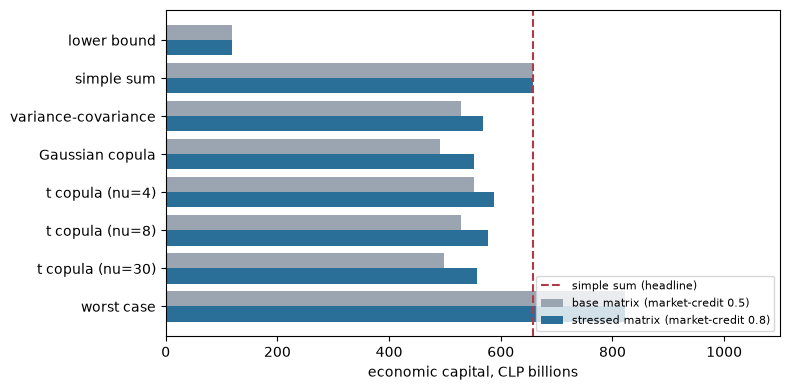

In [9]:
# Draw the committed band under the base and the stressed correlation matrix, with the headline as a vertical line
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum", "variance-covariance": "variance-covariance",
         "gaussian-copula": "Gaussian copula", "t-copula": "t copula", "worst-case": "worst case"}
keys = list(committed)
labels = [NAMES[k[0]] + (f" (nu={k[1]:g})" if k[1] else "") for k in keys]
y = np.arange(len(keys))[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y + 0.2, [committed[k]["capital_clp_m"] / 1e3 for k in keys], height=0.4, color="#9aa5b1", label="base matrix (market-credit 0.5)")
ax.barh(y - 0.2, [stressed[k]["capital_clp_m"] / 1e3 for k in keys], height=0.4, color="#2a6f97", label="stressed matrix (market-credit 0.8)")
ax.axvline(agg["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("economic capital, CLP billions")
ax.set_xlim(0, 1100)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

- **The comonotonic VaR of the published example is 72.0, equal to its formula, and the worst VaR is 141.66 to 141.67, 1.97 times larger** (the best VaR is 9.00): the rearrangement runs converged in 4 to 5 sweeps. Perfect dependence is far from the worst case.
- **The rearrangement raises the smallest row sum of the small matrix from 27.8 to 45.4** and brings the row sums to a narrow range (45.4 to 62.8, against 27.8 to 131.2), without changing any column's values.
- **On the rebuilt marginals every row of the band comes back.** The simple sum and the square-root row equal the committed ones (658,046 and 528,106 CLP millions), because they use only the committed capitals. The lower bound is 118,509 against 118,518 and the worst case 823,347 against 823,332, both within 0.01 percent, and the Gaussian and t rows are those of notebook 02 (491,999 against 491,974 for the Gaussian copula).
- **The structural rule holds where it should.** `worst_case_bracket` is green on the committed band (worst less lower 704,814, 1.0711 times the largest row) and on this notebook's band (704,838, 1.0711 times), and red when the Gaussian row is doubled out of the bracket (one row outside).
- **The correlation stress moves only the rows that use the matrix.** With market-credit 0.8 the square-root row rises 7.7 percent (to 568,521, which the engine recomputes from the stressed matrix), the Gaussian row 12.1 percent, and the t rows 6.4, 9.2 and 11.6 percent for $\nu = 4$, 8 and 30; the lower bound, the simple sum and the worst case do not move at all. The engine's `correlation_stress` test reads the Gaussian change, 12.11 percent, against its 10 percent gate and turns amber.

What this notebook does not show: the million-draw samples, which are not committed, so the marginals come from a grid of 1,961 points and the rows agree to 0.01 percent and not to the digit; and a worst case computed on marginals is exact only as far as the marginals are right in their upper tail, here to the grid's reach, 4.8e-7 from the end.

## Summary

- The comonotonic VaR is the VaR of perfectly dependent risks and is not the worst case, because a VaR is not subadditive; the rearrangement algorithm gives the sharp best and worst VaR for known marginals and any dependence.
- The algorithm only permutes values inside each column and aims at equal row sums, which spreads the extremes so that every scenario is bad.
- The band shows, over the same marginals, horizon and level, the lower bound, the simple sum (the headline), the square-root rule, the Gaussian copula, a t copula per degree of freedom and the worst case, each labelled headline or information.
- The bounds and the simple sum do not depend on the correlation matrix; the other rows do, and the matrix is a convention.
- Every row lies inside the bracket, which `worst_case_bracket` checks and turns red when it fails.

**What to try next.** Change `bounds_n` in step 4 to 10,000 and see how much the worst case moves; then continue with notebook 04, which turns macro scenarios into the loss rates that feed the credit marginal.

## References

- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Embrechts, P., McNeil, A. and Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, in Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- This repository: `docs/contracts/engine/aggregation-api.md` (the band, the bounds and the validation tests).